<a href="https://colab.research.google.com/github/Aakanksha-sengar/online-retail-rfm-analysis/blob/main/notebooks/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Online Retail: RFM Analysis & Customer Segmentation

**Goal:** group the customers of an online retailer by their buying behaviour so the business knows whom to reward, nurture or win back.

**Approach:** clean the transaction data, compute **Recency, Frequency and Monetary (RFM)** values per customer, then use **K-Means clustering** to form segments and profile them.

| Metric | Meaning |
|---|---|
| **Recency** | days since the customer's last purchase |
| **Frequency** | number of distinct orders |
| **Monetary** | total money spent |

**Dataset:** [Online Retail, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) (UK-based online retailer, 1 Dec 2010 to 9 Dec 2011). Put the file `Online Retail.xlsx` in the same folder as this notebook (in Colab: upload it from the left *Files* panel).

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

os.makedirs("outputs", exist_ok=True)      # charts and the Excel report are saved here
RANDOM_STATE = 42

# One fixed colour per segment, used in every chart
SEG_ORDER = ["Champions", "Regular Customers", "New / Low-Spend", "Lost / Churned"]
SEG_COLORS = dict(zip(SEG_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e5e5e3"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
print("Setup complete")

Setup complete


## 2. Load the data

In [2]:
df_raw = pd.read_excel("Online Retail.xlsx")
print("Rows, columns:", df_raw.shape)
df_raw.head()

Rows, columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 3. Data quality check
Before cleaning, check what is wrong with the data. Every cleaning decision below is based on this table.

In [4]:
inv = df_raw["InvoiceNo"].astype(str)

quality = pd.DataFrame({
    "Check": [
        "Missing CustomerID",
        "Missing Description",
        "Cancelled invoices (InvoiceNo starts with 'C')",
        "Quantity <= 0",
        "UnitPrice <= 0",
        "Exact duplicate rows",
    ],
    "Rows": [
        df_raw["CustomerID"].isna().sum(),
        df_raw["Description"].isna().sum(),
        inv.str.startswith("C").sum(),
        (df_raw["Quantity"] <= 0).sum(),
        (df_raw["UnitPrice"] <= 0).sum(),
        df_raw.duplicated().sum(),
    ],
})
quality["% of data"] = (quality["Rows"] / len(df_raw) * 100).round(1)
quality

,Check,Rows,% of data
0,Missing CustomerID,135080,24.9
1,Missing Description,1454,0.3
2,Cancelled invoices (InvoiceNo starts with 'C'),9288,1.7
3,Quantity <= 0,10624,2.0
4,UnitPrice <= 0,2517,0.5
5,Exact duplicate rows,5268,1.0


## 4. Data cleaning
| Decision | Reason |
|---|---|
| Drop rows with no `CustomerID` | RFM is calculated per customer, so these rows cannot be used |
| Keep only `Quantity > 0` and `UnitPrice > 0` | Removes cancellations, returns and price errors |
| Drop exact duplicate rows | The same line item recorded twice would inflate Frequency and Monetary |
| Create `Revenue = Quantity x UnitPrice` | Needed for Monetary |

In [5]:
steps = [("Original data", len(df_raw))]

df = df_raw.dropna(subset=["CustomerID"])
steps.append(("After removing missing CustomerID", len(df)))

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
steps.append(("After removing Quantity <= 0 / UnitPrice <= 0", len(df)))

df = df.drop_duplicates().copy()
steps.append(("After removing duplicate rows", len(df)))

df["Revenue"] = df["Quantity"] * df["UnitPrice"]

cleaning_log = pd.DataFrame(steps, columns=["Step", "Rows remaining"])
cleaning_log["Rows removed"] = (-cleaning_log["Rows remaining"].diff()).fillna(0).astype(int)

print(f"Clean data: {len(df):,} rows ({len(df) / len(df_raw):.1%} of original)")
print(f"Customers: {df['CustomerID'].nunique():,} | Orders: {df['InvoiceNo'].nunique():,}")
print(f"Total revenue: £{df['Revenue'].sum():,.0f}")
cleaning_log

Clean data: 392,692 rows (72.5% of original)
Customers: 4,338 | Orders: 18,532
Total revenue: £8,887,209


,Step,Rows remaining,Rows removed
0,Original data,541909,0
1,After removing missing CustomerID,406829,135080
2,After removing Quantity <= 0 / UnitPrice <= 0,397884,8945
3,After removing duplicate rows,392692,5192


## 5. Quick exploration

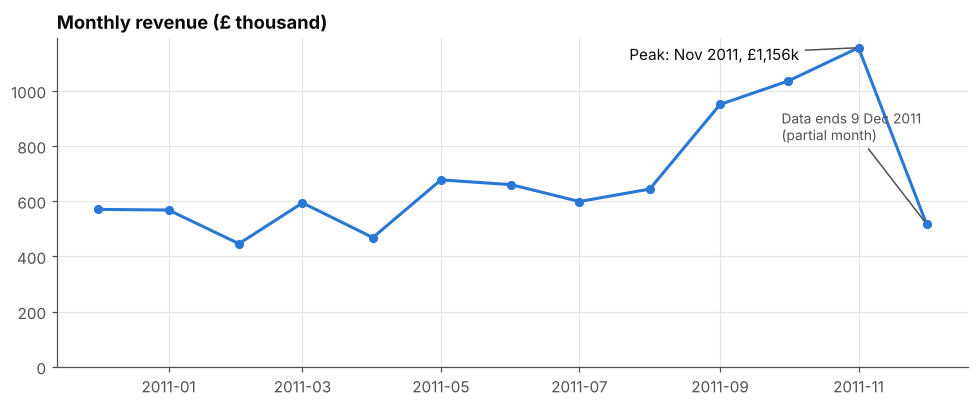

In [6]:
monthly = df.set_index("InvoiceDate")["Revenue"].resample("MS").sum() / 1e3

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(monthly.index, monthly.values, color=BLUE, lw=2, marker="o", ms=5)
ax.set_ylim(0)
ax.set_title("Monthly revenue (£ thousand)")
peak = monthly.idxmax()
ax.annotate(f"Peak: {peak:%b %Y}, £{monthly.max():,.0f}k", xy=(peak, monthly.max()),
            xytext=(-150, -8), textcoords="offset points", color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate("Data ends 9 Dec 2011\n(partial month)", xy=(monthly.index[-1], monthly.values[-1]),
            xytext=(-95, 55), textcoords="offset points", color=MUTED, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED))
plt.tight_layout()
plt.savefig("outputs/monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

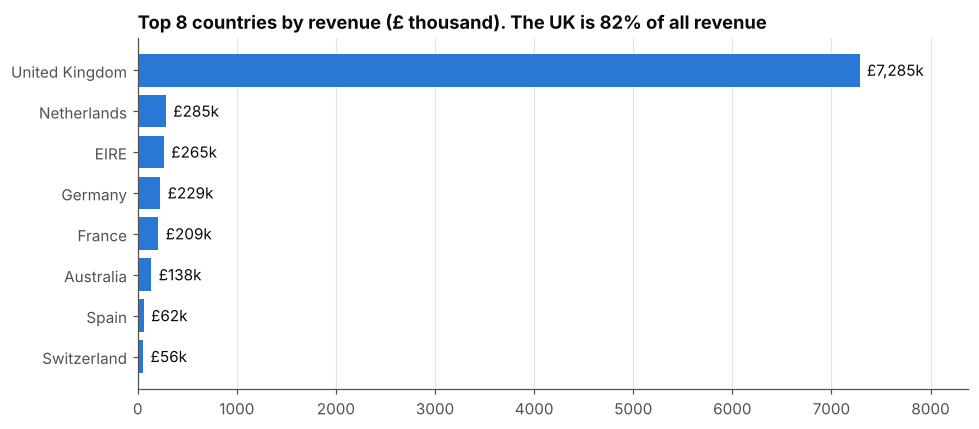

In [7]:
country = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = country["United Kingdom"] / country.sum()
top = (country.head(8) / 1e3)[::-1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top.index, top.values, color=BLUE)
for y, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, y, f"£{v:,.0f}k", va="center", color=INK)
ax.set_xlim(0, top.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title(f"Top 8 countries by revenue (£ thousand). The UK is {uk_share:.0%} of all revenue")
plt.tight_layout()
plt.savefig("outputs/top_countries.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Build the RFM table
Reference date = the day after the last transaction in the data. **Monetary is the sum of `Revenue`** over all of a customer's orders.

In [8]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Reference date:", snapshot_date)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)
rfm.index = rfm.index.astype(int)

print(f"Customers: {len(rfm):,}")
rfm.describe().round(2)

Reference date: 2011-12-10 12:50:00


Customers: 4,338


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


In [9]:
cols = ["Recency", "Frequency", "Monetary"]
print("Skewness (raw):", rfm[cols].skew().round(2).to_dict())

# How concentrated is revenue?
sorted_m = rfm["Monetary"].sort_values(ascending=False)
top20_share = sorted_m.head(int(len(sorted_m) * 0.2)).sum() / sorted_m.sum()
print(f"Top 20% of customers generate {top20_share:.1%} of revenue")

Skewness (raw): {'Recency': 1.25, 'Frequency': 12.07, 'Monetary': 19.34}
Top 20% of customers generate 74.7% of revenue


## 7. Prepare features for clustering
Frequency and Monetary are extremely right-skewed: a few customers buy hundreds of times or spend hundreds of thousands. K-Means uses distances, so those few customers would dominate the clusters. Two steps fix this:

1. **Log transform** (`log1p`) to compress the long tail
2. **Standardization** so all three metrics have equal weight

Skewness after log: {'Recency': -0.38, 'Frequency': 1.21, 'Monetary': 0.4}


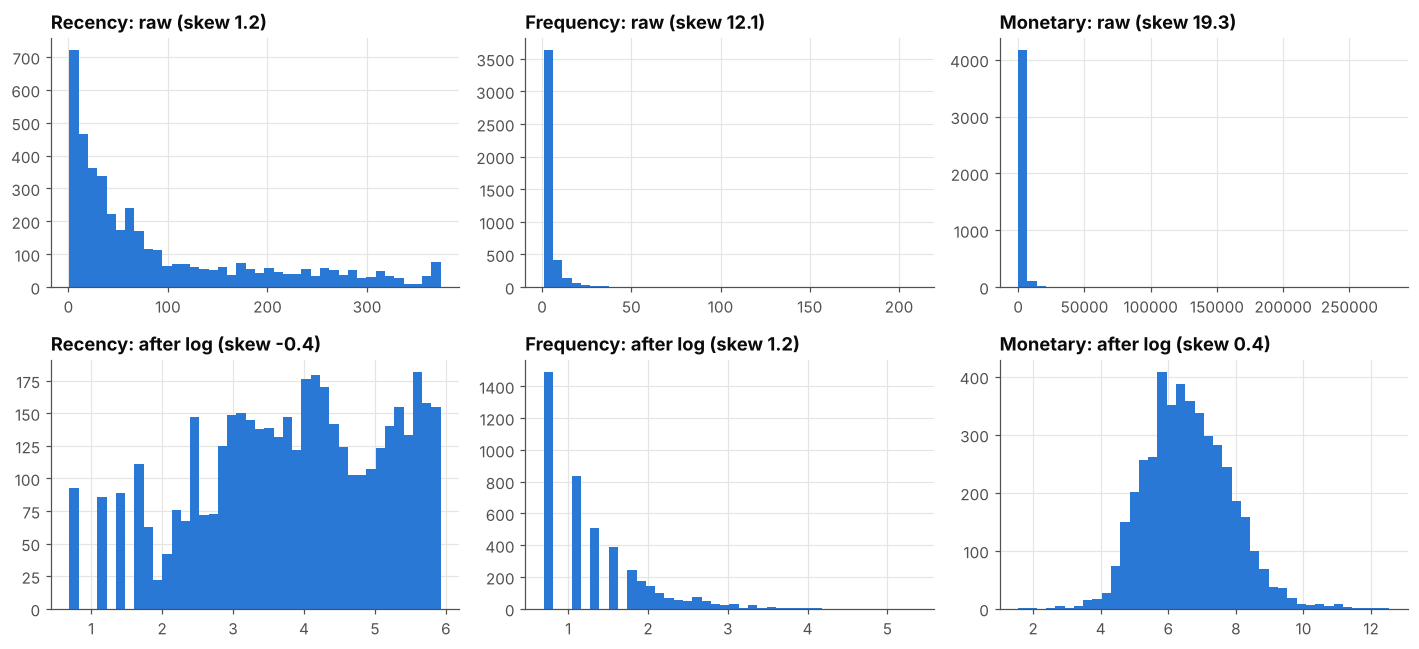

In [10]:
rfm_log = np.log1p(rfm[cols])
print("Skewness after log:", rfm_log.skew().round(2).to_dict())

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, c in enumerate(cols):
    axes[0, j].hist(rfm[c], bins=40, color=BLUE)
    axes[0, j].set_title(f"{c}: raw (skew {rfm[c].skew():.1f})")
    axes[1, j].hist(rfm_log[c], bins=40, color=BLUE)
    axes[1, j].set_title(f"{c}: after log (skew {rfm_log[c].skew():.1f})")
plt.tight_layout()
plt.savefig("outputs/rfm_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

rfm_scaled = StandardScaler().fit_transform(rfm_log)

## 8. Choose the number of clusters
Two checks: the **elbow method** (WCSS drops sharply and then flattens) and the **silhouette score** (higher means better separated clusters).

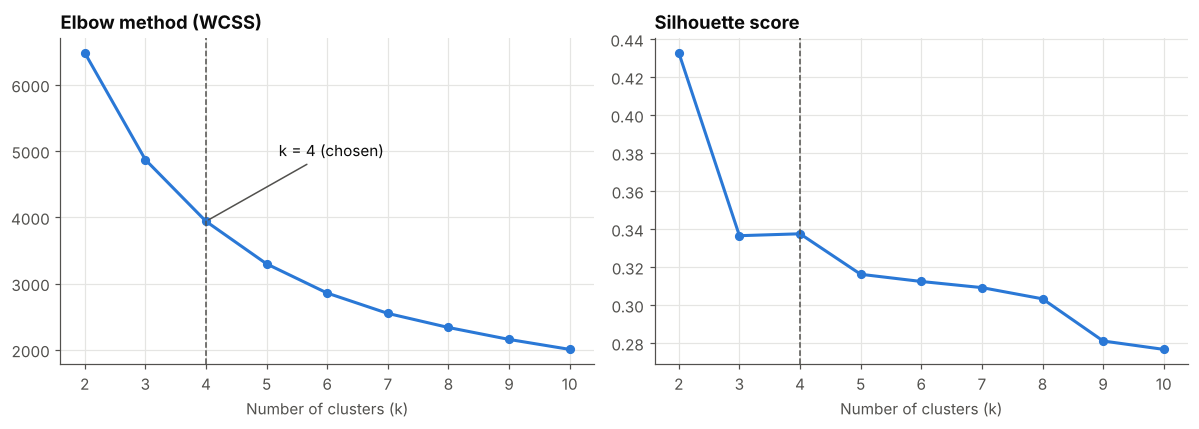

,k,WCSS,Silhouette
0,2,6483.6,0.433
1,3,4869.5,0.337
2,4,3939.0,0.338
3,5,3296.7,0.316
4,6,2855.8,0.312
5,7,2548.8,0.309
6,8,2336.3,0.303
7,9,2156.0,0.281
8,10,2005.7,0.277


In [11]:
ks = range(2, 11)
wcss, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(rfm_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(rfm_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, y, title in zip(axes, [wcss, sil], ["Elbow method (WCSS)", "Silhouette score"]):
    ax.plot(list(ks), y, color=BLUE, lw=2, marker="o", ms=5)
    ax.axvline(4, color=MUTED, ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
axes[0].annotate("k = 4 (chosen)", xy=(4, wcss[2]), xytext=(5.2, wcss[2] * 1.25),
                 color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
plt.tight_layout()
plt.savefig("outputs/elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"k": list(ks), "WCSS": np.round(wcss, 1), "Silhouette": np.round(sil, 3)})

**Why k = 4?** The silhouette score is highest at k = 2, but two groups (valuable vs. not valuable) are too coarse for marketing decisions. From k = 3 onwards the score is nearly flat, and k = 4 is where the elbow bends while still giving segments that are easy to explain and act on. This is a business-driven choice, and the trade-off is stated here on purpose.

## 9. Final K-Means model and segment profiles

In [12]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Revenue=("Monetary", "sum"),
).round(1)
profile["Customers %"] = (profile["Customers"] / profile["Customers"].sum() * 100).round(1)
profile["Revenue %"] = (profile["Revenue"] / profile["Revenue"].sum() * 100).round(1)
profile

,Customers,Recency,Frequency,Monetary,Revenue,Customers %,Revenue %
Cluster,,,,,,,
0,713,12.2,13.8,8088.0,5766757.1,16.4,64.9
1,1622,181.5,1.3,341.0,553099.8,37.4,6.2
2,837,17.7,2.2,557.3,466479.0,19.3,5.2
3,1166,71.6,4.1,1801.8,2100873.0,26.9,23.6


Cluster numbers are arbitrary, so segments are named from their profile instead:

- highest average spend = **Champions**
- longest time since last purchase = **Lost / Churned**
- of the remaining two, the more recent buyers = **New / Low-Spend**, the other = **Regular Customers**

In [13]:
champ = profile["Monetary"].idxmax()
lost = profile["Recency"].idxmax()
rest = profile.drop([champ, lost])
new_low = rest["Recency"].idxmin()

names = {champ: "Champions", lost: "Lost / Churned", new_low: "New / Low-Spend"}
names.update({c: "Regular Customers" for c in rest.index if c != new_low})

rfm["Segment"] = rfm["Cluster"].map(names)
summary = profile.rename(index=names).loc[SEG_ORDER]
summary

,Customers,Recency,Frequency,Monetary,Revenue,Customers %,Revenue %
Cluster,,,,,,,
Champions,713,12.2,13.8,8088.0,5766757.1,16.4,64.9
Regular Customers,1166,71.6,4.1,1801.8,2100873.0,26.9,23.6
New / Low-Spend,837,17.7,2.2,557.3,466479.0,19.3,5.2
Lost / Churned,1622,181.5,1.3,341.0,553099.8,37.4,6.2


## 10. Segment visualizations
Frequency and Monetary use a log scale because of the heavy outliers.

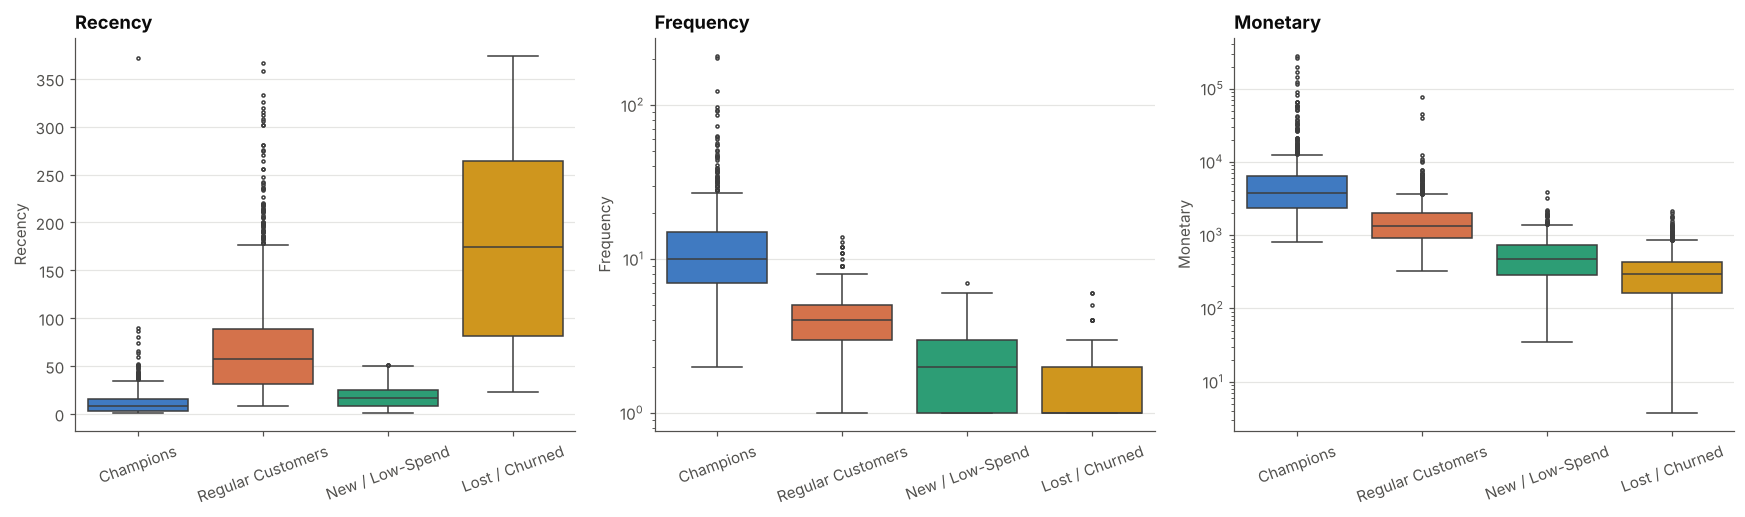

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, c in zip(axes, cols):
    sns.boxplot(data=rfm, x="Segment", y=c, order=SEG_ORDER, hue="Segment", hue_order=SEG_ORDER,
                palette=SEG_COLORS, legend=False, linewidth=1, fliersize=2, ax=ax)
    if c != "Recency":
        ax.set_yscale("log")
    ax.set_title(c)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("outputs/rfm_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

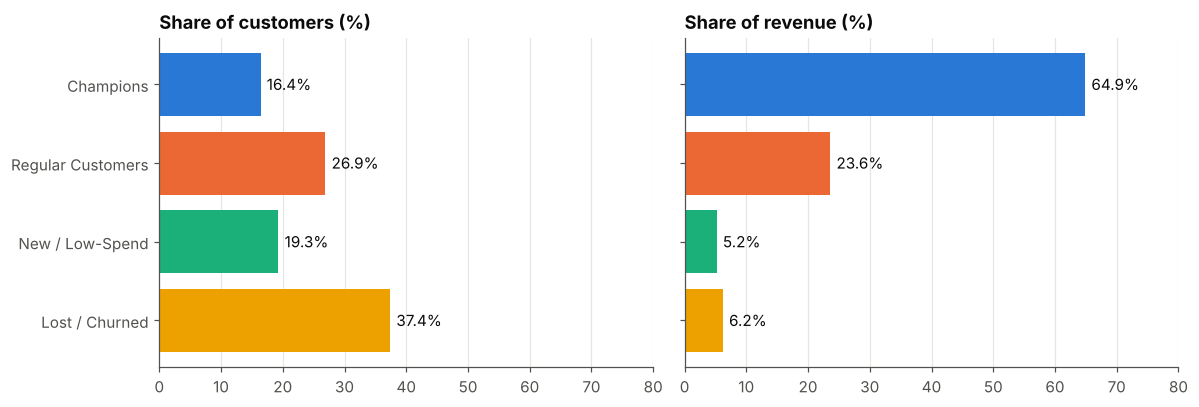

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (col, title) in zip(axes, [("Customers %", "Share of customers (%)"),
                                   ("Revenue %", "Share of revenue (%)")]):
    vals = summary[col]
    ax.barh(SEG_ORDER, vals.values, color=[SEG_COLORS[s] for s in SEG_ORDER])
    for y, v in enumerate(vals.values):
        ax.text(v + 1, y, f"{v:.1f}%", va="center", color=INK)
    ax.set_xlim(0, 80)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/segment_share.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Insights and recommendations

**Insights**
- **Revenue is concentrated.** The Champions segment is about 16% of customers but generates about 65% of revenue.
- **A large part of the base has gone quiet.** The Lost / Churned segment is about 37% of customers, last bought about 6 months ago on average, and brings only about 6% of revenue.
- **Regular Customers are the opportunity.** They order about 4 times on average but have not bought for about 72 days, so they can still be won back.

**Recommended actions**

| Segment | Suggested action |
|---|---|
| Champions | Loyalty programme and early access to new products; avoid unnecessary discounting |
| Regular Customers | Re-engagement emails and personalised offers before they drift away |
| New / Low-Spend | Welcome series and an incentive for the second purchase |
| Lost / Churned | Low-cost win-back campaign; limit spend on this group |

## 12. Export results to Excel
The workbook has three sheets: customer-level RFM scores with segments, a segment summary, and the cleaning log.

In [16]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

customers_out = rfm.reset_index()[["CustomerID", "Recency", "Frequency", "Monetary", "Cluster", "Segment"]]
customers_out["Monetary"] = customers_out["Monetary"].round(2)
summary_out = summary.reset_index().rename(columns={"Cluster": "Segment"})

path = "outputs/rfm_segments.xlsx"
with pd.ExcelWriter(path, engine="openpyxl") as writer:
    customers_out.to_excel(writer, sheet_name="Customers", index=False)
    summary_out.to_excel(writer, sheet_name="Segment Summary", index=False)
    cleaning_log.to_excel(writer, sheet_name="Cleaning Log", index=False)

    for ws in writer.book.worksheets:
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="2A78D6")
            cell.alignment = Alignment(horizontal="center")
        ws.freeze_panes = "A2"
        for i, col_cells in enumerate(ws.columns, start=1):
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col_cells)
            ws.column_dimensions[get_column_letter(i)].width = min(max(width + 3, 12), 48)
        for row in ws.iter_rows(min_row=2):
            for c in row:
                if isinstance(c.value, float):
                    c.number_format = "#,##0.0" if ws.title == "Segment Summary" else "#,##0.00"
                elif isinstance(c.value, int) and ws.title == "Cleaning Log":
                    c.number_format = "#,##0"

print("Saved:", path)
print("Files in outputs/:", sorted(os.listdir("outputs")))

Saved: outputs/rfm_segments.xlsx
Files in outputs/: ['elbow_silhouette.png', 'monthly_revenue.png', 'rfm_boxplots.png', 'rfm_distributions.png', 'rfm_segments.xlsx', 'segment_share.png', 'top_countries.png']


## 13. Limitations
- About 25% of rows have no `CustomerID` and could not be used in the customer analysis.
- The data covers one year of a single retailer, and the UK accounts for most of the revenue. Many customers are wholesalers, which explains the very large spenders.
- K-Means results depend on the chosen k and on feature scaling. The segment names are interpretations of the cluster profiles.
- December 2011 is a partial month, so Recency is measured against 10 Dec 2011.